<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_087_vanishing_exploding_gradients.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 87/365 — Vanishing & Exploding Gradients

Yesterday we learned **Backpropagation**.

During backpropagation, derivatives are multiplied as gradients travel backward through layers.

That creates two famous problems:

- **Vanishing gradients** — gradients become tiny.
- **Exploding gradients** — gradients become huge.


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Tiny numerical intuition

If a gradient is multiplied by `0.5` across 10 layers:

`0.5^10 ≈ 0.001`

Almost nothing reaches the early layers.

If it is multiplied by `1.5` across 10 layers:

`1.5^10 ≈ 57.7`

The gradient can become unstable.


In [2]:
print("0.5^10 =", 0.5**10)
print("1.5^10 =", 1.5**10)


0.5^10 = 0.0009765625
1.5^10 = 57.6650390625


## 2. Vanishing gradients

When gradients become extremely small:

- early layers learn very slowly
- weight updates become tiny
- deep networks become difficult to train

Sigmoid and Tanh can contribute because their derivatives become small in saturated regions.


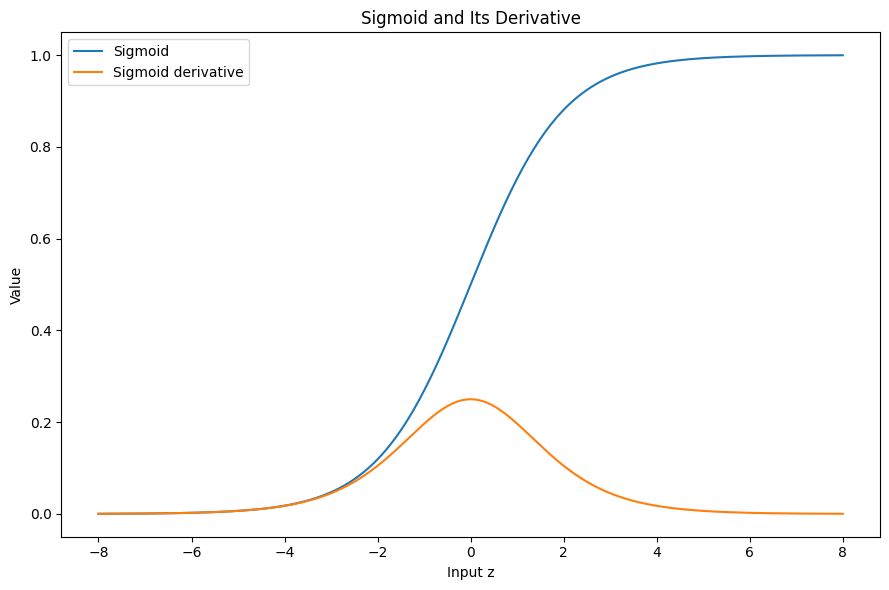

In [3]:
x=np.linspace(-8,8,400)
sigmoid=1/(1+np.exp(-x))
sigmoid_grad=sigmoid*(1-sigmoid)

plt.figure(figsize=(9,6))
plt.plot(x,sigmoid,label="Sigmoid")
plt.plot(x,sigmoid_grad,label="Sigmoid derivative")
plt.xlabel("Input z")
plt.ylabel("Value")
plt.title("Sigmoid and Its Derivative")
plt.legend()
plt.tight_layout()
plt.show()


## 3. Exploding gradients

When gradients become extremely large:

- weight updates can become huge
- training becomes unstable
- loss may jump wildly
- numerical overflow / NaNs can appear


## 4. Common fixes

### Better activation functions
ReLU and GELU reduce some saturation problems.

### Better initialization
Xavier and He initialization help keep signal scales healthier.

### Batch Normalization
Helps stabilize activations during training.

### Residual Connections
Give gradients shorter paths through deep networks.

### Gradient Clipping
Caps gradient magnitude and is especially useful for exploding gradients.


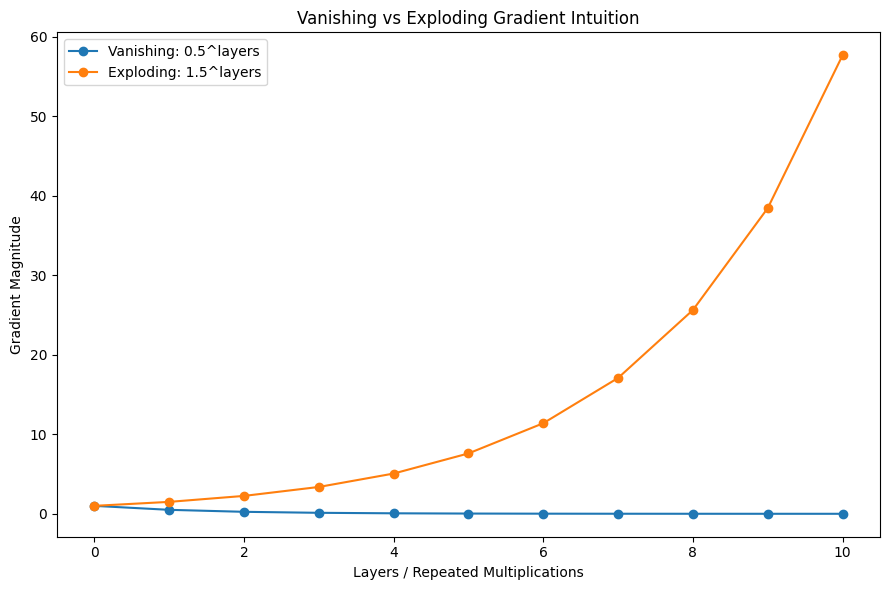

In [4]:
layers=np.arange(0,11)

plt.figure(figsize=(9,6))
plt.plot(layers,0.5**layers,marker="o",label="Vanishing: 0.5^layers")
plt.plot(layers,1.5**layers,marker="o",label="Exploding: 1.5^layers")
plt.xlabel("Layers / Repeated Multiplications")
plt.ylabel("Gradient Magnitude")
plt.title("Vanishing vs Exploding Gradient Intuition")
plt.legend()
plt.tight_layout()
plt.show()


## Simple takeaway

Backpropagation depends on healthy gradient flow.

Repeatedly multiplying values below 1 can shrink the gradient.

Repeatedly multiplying large values can make it explode.

> **A deep network can only learn if useful gradient information can travel all the way back through its layers.**


## References

- https://www.deeplearningbook.org/
- https://proceedings.mlr.press/v9/glorot10a.html
- https://arxiv.org/abs/1502.01852
